# Búsqueda de columnas redundantes (Issue 3)

**Objetivo:** encontrar columnas que no aportan información nueva y decidir, con una justificación, cuál se conserva de cada grupo.

Se revisan cinco tipos de redundancia:

1. Columnas vacías (100 % de nulos).
2. Columnas casi constantes: el valor más frecuente ocupa al menos el 99 % de los valores **observados**.
3. Columnas duplicadas exactas.
4. Columnas numéricas colineales, con |Pearson| o |Spearman| ≥ 0.90, y columnas derivadas de otras.
5. Columnas categóricas redundantes, medidas con la V de Cramér y el coeficiente de incertidumbre de Theil.

**Reglas:**

- Todo el análisis y el ajuste del `EliminadorRedundantes` usan solo `entrenamiento` (64 %).
- `validacion` (16 %) solo se usa al final, para comprobar que eliminar columnas no empeora el modelo.
- `prueba` no se usa.
- Los nulos que no llegan al 100 % no se tocan; se reportan para el Issue 5. Esto incluye `sec_app_*`, `*_joint` y `desc`.

El código reutilizable está en [`src/features.py`](../src/features.py).

> **Antes de ejecutar:** la primera celda ejecuta [`issue2.ipynb`](issue2.ipynb), que carga el dataset con `src/data.py`.
>
> **Para los issues 4 y 5:** al final (sección 10) se quitan las columnas redundantes de `X_train`, `X_val` y `X_test`. El Issue 4 empieza con `%run issue3.ipynb` y el Issue 5 con `%run issue4.ipynb`, así que ambos trabajan sin estas columnas.

In [1]:
# Carga el checkpoint de issue2 (data/checkpoints/issue2/) en lugar de ejecutar toda la cadena.
# Si no existe, se ejecuta issue2.ipynb, que lo genera al terminar.
import sys
sys.path.append('..')
from src.data import cargar_prestamos, particionar
from src.checkpoints import cargar_checkpoint, existe_checkpoint

if existe_checkpoint('issue2'):
    globals().update(cargar_checkpoint('issue2'))
    # El análisis de redundancia usa todas las columnas: se leen de la caché Parquet.
    entrenamiento, validacion, prueba = particionar(cargar_prestamos())
else:
    %run issue2.ipynb

Checkpoint issue2 cargado: X_train (862757, 76), X_val (215690, 76), X_test (269612, 76), y_train (862757,), y_val (215690,), y_test (269612,)


In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

sys.path.append(str(Path.cwd().parent))
from src.data import COLUMNAS_EXCLUIDAS, SEED, cargar_prestamos, particionar, separar_X_y
from src.features import (
    REDUNDANTES_CATEGORICAS, UMBRAL_CORRELACION, UMBRAL_DOMINANCIA,
    EliminadorRedundantes, columnas_duplicadas, matriz_correlacion,
    normalizar_texto, pares_correlacionados, perfil_columnas, u_theil, v_cramer,
)

pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.max_rows', 120)

DIR_FIGURAS = Path.cwd().parent / 'reports' / 'figures'
AZUL, NARANJA, TINTA, TINTA_2, REJILLA = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e', '#e4e3df'
SECUENCIAL = LinearSegmentedColormap.from_list('azules', ['#fcfcfb', '#86b6ef', '#2a78d6', '#0d366b'])
plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'axes.edgecolor': TINTA_2,
    'axes.labelcolor': TINTA, 'xtick.color': TINTA_2, 'ytick.color': TINTA_2,
    'axes.grid': True, 'grid.color': REJILLA, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10,
    'axes.titlesize': 12, 'axes.titleweight': 'bold',
})

def guardar(fig, nombre):
    ruta = DIR_FIGURAS / nombre
    fig.savefig(ruta, dpi=150, bbox_inches='tight')
    print(f'Figura guardada en reports/figures/{nombre}')

## 1. Datos

Se reutilizan `entrenamiento` y `validacion` de `issue2.ipynb`. El análisis parte de las 100 columnas candidatas de `separar_X_y` (sin `target`, `particion`, `issue_d` ni `loan_amnt`, que es condicional), antes de la limpieza de `issue2`, para que los criterios de este issue se apliquen a todas.

In [3]:
# entrenamiento y validacion vienen de issue2.ipynb (prueba no se usa)
X_ent, y_ent = separar_X_y(entrenamiento)
print(f'Entrenamiento: {X_ent.shape[0]:,} préstamos, {X_ent.shape[1]} columnas candidatas')
print(f'Charged Off en entrenamiento: {y_ent.mean():.2%}')
print(X_ent.dtypes.map(lambda t: 'numérica' if pd.api.types.is_numeric_dtype(t) else 'categórica/texto').value_counts().to_string())

Entrenamiento: 862,757 préstamos, 100 columnas candidatas
Charged Off en entrenamiento: 19.98%
numérica            85
categórica/texto    15


### Verificación de leakage

El leakage ya se eliminó en `src/data.py`. Aquí solo se comprueba que ninguna columna prohibida haya llegado a los datos:

- 38 columnas de pagos, recuperación, hardship y settlement.
- `int_rate`, `installment`, `grade`, `sub_grade`, `funded_amnt`, `funded_amnt_inv` e `initial_list_status`, que se fijan después de aprobar el crédito.
- Los identificadores.

Por eso `funded_amnt`, `funded_amnt_inv` y `sub_grade` ya no aparecen en los datos, aunque son redundantes con `loan_amnt` y `grade`. La misma comprobación se ejecuta dentro de `EliminadorRedundantes.fit`.

In [4]:
prohibidas = sorted(set(COLUMNAS_EXCLUIDAS) & set(X_ent.columns))
assert not prohibidas, prohibidas
print(f'Ninguna de las {len(COLUMNAS_EXCLUIDAS)} columnas excluidas está en X_ent.')

Ninguna de las 48 columnas excluidas está en X_ent.


## 2. Perfil de columnas: vacías y casi constantes

La dominancia se calcula **sin contar los NaN**. Si se contaran, las columnas del segundo solicitante (`sec_app_*`) aparecerían como casi constantes, porque tienen 98.6 % de nulos al aplicar solo a solicitudes conjuntas. Su valor dominante sería NaN, cuando en realidad varían entre los préstamos conjuntos.

In [5]:
perfil = perfil_columnas(X_ent, y_ent)
tasa_global = perfil.attrs['tasa_default_global']
vacias = perfil.index[perfil['pct_nulos'] >= 100]
print(f'Columnas 100 % vacías: {list(vacias) or "ninguna"}')

casi_constantes = perfil.loc[perfil['dominancia'] >= UMBRAL_DOMINANCIA].sort_values('dominancia', ascending=False)
print(f'\nCasi constantes (dominancia >= {UMBRAL_DOMINANCIA:.0%}); tasa global de Charged Off = {tasa_global:.2%}')
casi_constantes[['tipo', 'pct_nulos', 'valor_dominante', 'dominancia', 'n_no_dominante', 'tasa_default_no_dominante']].round(4)

Columnas 100 % vacías: ninguna

Casi constantes (dominancia >= 99%); tasa global de Charged Off = 19.98%


,tipo,pct_nulos,valor_dominante,dominancia,n_no_dominante,tasa_default_no_dominante
columna,,,,,,
policy_code,numérica,0.0000,1.0,1.0000,0,NaN
num_tl_120dpd_2m,numérica,8.9308,0.0,0.9992,609,0.2003
num_tl_30dpd,numérica,5.2211,0.0,0.9968,2617,0.2258
delinq_amnt,numérica,0.0023,0.0,0.9963,3183,0.2347
acc_now_delinq,numérica,0.0023,0.0,0.9953,4018,0.2232
disbursement_method,categórica,0.0000,Cash,0.9949,4375,0.1991
chargeoff_within_12_mths,numérica,0.0116,0.0,0.9920,6929,0.2165


Las 7 columnas casi constantes son 4 conteos de cuentas en mora (`acc_now_delinq`, `num_tl_30dpd`, `num_tl_120dpd_2m`, `chargeoff_within_12_mths`), `delinq_amnt`, `policy_code` (constante) y `disbursement_method`.

En los conteos de mora y en `delinq_amnt`, el pequeño grupo con valor distinto de 0 tiene una tasa de `Charged Off` igual o algo mayor que la global: entre 20.0 % y 23.5 %, frente a 19.98 %. Es una señal pequeña, que afecta como mucho al 0.8 % de los préstamos (6,929 en `chargeoff_within_12_mths`). En `disbursement_method`, el grupo minoritario (`DirectPay`) tiene la misma tasa que la global: 19.9 %. Además, ya la recogen otras variables de morosidad que se conservan: `delinq_2yrs`, `num_tl_90g_dpd_24m`, `num_accts_ever_120_pd` y `pct_tl_nvr_dlq`. Se aplica el umbral acordado y se eliminan. Si el modelado final lo necesita, podrían recuperarse como un indicador binario de "alguna mora actual".

En cambio, las columnas con muchos nulos **no se eliminan**. Se reportan para el Issue 5:

In [6]:
muchos_nulos = perfil.loc[(perfil['pct_nulos'] >= 50) & (perfil['pct_nulos'] < 100), ['tipo', 'pct_nulos', 'n_unicos', 'dominancia']]
print(f'{len(muchos_nulos)} columnas con 50 % a 99.9 % de nulos (quedan para el Issue 5):')
muchos_nulos.sort_values('pct_nulos', ascending=False).round(2)

36 columnas con 50 % a 99.9 % de nulos (quedan para el Issue 5):


,tipo,pct_nulos,n_unicos,dominancia
columna,,,,
sec_app_mths_since_last_major_derog,numérica,99.50,106,0.03
sec_app_revol_util,numérica,98.63,1085,0.01
sec_app_fico_range_high,numérica,98.61,60,0.06
sec_app_fico_range_low,numérica,98.61,60,0.06
sec_app_earliest_cr_line,categórica,98.61,539,0.01
revol_bal_joint,numérica,98.61,10877,0.00
sec_app_num_rev_accts,numérica,98.61,62,0.06
sec_app_inq_last_6mths,numérica,98.61,7,0.56
sec_app_mort_acc,numérica,98.61,17,0.37


Figura guardada en reports/figures/redundancia_dominancia.png


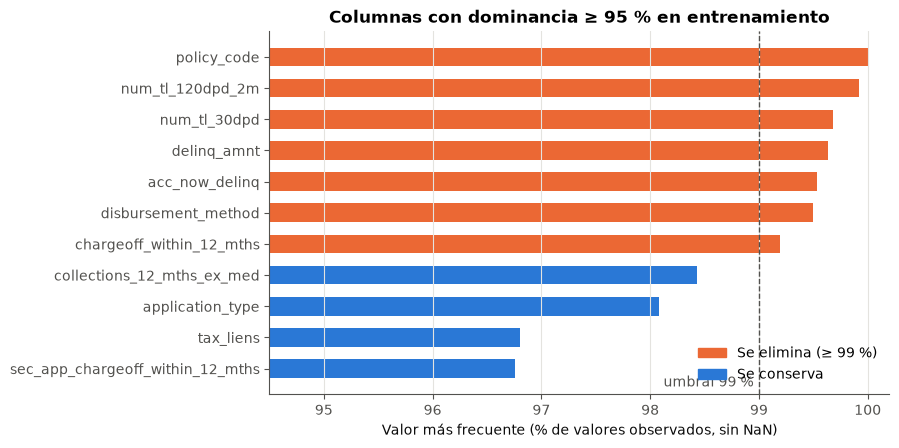

In [7]:
dominantes = perfil.loc[perfil['dominancia'] >= 0.95, 'dominancia'].sort_values()
fig, ax = plt.subplots(figsize=(8, 0.32 * len(dominantes) + 1.2))
colores = [NARANJA if d >= UMBRAL_DOMINANCIA else AZUL for d in dominantes]
ax.barh(dominantes.index, dominantes * 100, color=colores, height=0.6)
ax.axvline(UMBRAL_DOMINANCIA * 100, color=TINTA_2, linestyle='--', linewidth=1)
ax.text(UMBRAL_DOMINANCIA * 100 - 0.05, -0.45, 'umbral 99 %', color=TINTA_2, va='center', ha='right')
ax.set_xlim(94.5, 100.2)
ax.set_xlabel('Valor más frecuente (% de valores observados, sin NaN)')
ax.set_title('Columnas con dominancia ≥ 95 % en entrenamiento')
ax.grid(axis='y', visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=NARANJA), plt.Rectangle((0, 0), 1, 1, color=AZUL)],
          labels=['Se elimina (≥ 99 %)', 'Se conserva'], loc='lower right', frameon=False)
guardar(fig, 'redundancia_dominancia.png')
plt.show()

## 3. Columnas duplicadas exactas

Se comparan los valores de cada par de columnas, NaN incluidos, usando un hash y confirmando con `equals`.

In [8]:
duplicadas = columnas_duplicadas(X_ent)
print(f'Grupos de columnas idénticas: {duplicadas or "ninguno"}')

Grupos de columnas idénticas: ninguno


## 4. Redundancia numérica: Pearson y Spearman

Pearson mide relación lineal y es sensible a valores extremos. Spearman mide relación monótona usando rangos, así que es más robusta para variables muy asimétricas como los saldos. Se marca un par si **cualquiera** de los dos alcanza 0.90 en valor absoluto.

Las correlaciones se calculan con una submuestra fija de 200,000 préstamos de entrenamiento (`random_state=42`), usando las observaciones completas de cada par.

In [9]:
numericas = X_ent.select_dtypes('number')
numericas = numericas.drop(columns=casi_constantes.index.intersection(numericas.columns))
pares = pares_correlacionados(numericas, UMBRAL_CORRELACION)
pares.round(3)

,,pearson,spearman,max_abs
columna_a,columna_b,,,
fico_range_low,fico_range_high,1.000,1.000,1.000
sec_app_fico_range_low,sec_app_fico_range_high,1.000,1.000,1.000
open_acc,num_sats,0.999,0.998,0.999
num_actv_rev_tl,num_rev_tl_bal_gt_0,0.982,0.990,0.990
tot_cur_bal,tot_hi_cred_lim,0.978,0.975,0.978
total_bal_il,total_il_high_credit_limit,0.956,0.959,0.959
tot_cur_bal,avg_cur_bal,0.835,0.928,0.928


### Los 5 pares semilla del Issue 3

`README_ISSUES.md` partía de 5 pares con Pearson ≥ 0.9, medidos en una muestra exploratoria que no separaba entrenamiento. Aquí se recalculan solo con entrenamiento:

In [10]:
SEMILLA = [
    ('fico_range_low', 'fico_range_high', 1.000),
    ('open_acc', 'num_sats', 0.999),
    ('num_actv_rev_tl', 'num_rev_tl_bal_gt_0', 0.982),
    ('tot_cur_bal', 'tot_hi_cred_lim', 0.970),
    ('total_bal_il', 'total_il_high_credit_limit', 0.956),
]
pearson = matriz_correlacion(numericas, 'pearson')
spearman = matriz_correlacion(numericas, 'spearman')
pd.DataFrame(
    [(a, b, ref, pearson.loc[a, b], spearman.loc[a, b], numericas[a].isna().mean() * 100, numericas[b].isna().mean() * 100)
     for a, b, ref in SEMILLA],
    columns=['columna_a', 'columna_b', 'pearson_issue', 'pearson_ent', 'spearman_ent', 'pct_nulos_a', 'pct_nulos_b'],
).round(3)

,columna_a,columna_b,pearson_issue,pearson_ent,spearman_ent,pct_nulos_a,pct_nulos_b
0,fico_range_low,fico_range_high,1.000,1.000,1.000,0.000,0.000
1,open_acc,num_sats,0.999,0.999,0.998,0.002,4.351
2,num_actv_rev_tl,num_rev_tl_bal_gt_0,0.982,0.982,0.990,5.221,5.221
3,tot_cur_bal,tot_hi_cred_lim,0.970,0.978,0.975,5.221,5.221
4,total_bal_il,total_il_high_credit_limit,0.956,0.956,0.959,60.101,5.221


Figura guardada en reports/figures/redundancia_pares_semilla.png


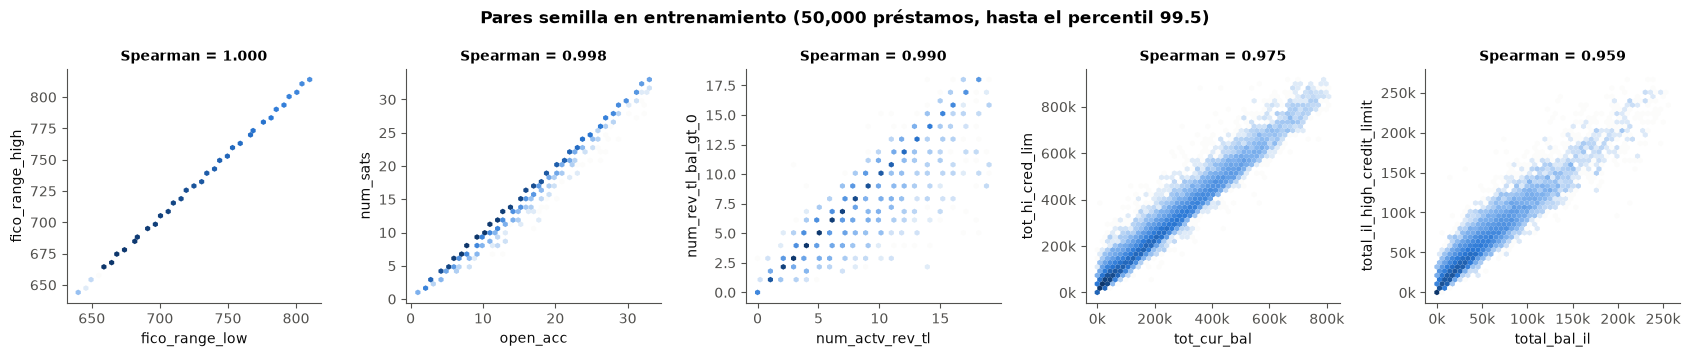

In [11]:
fig, ejes = plt.subplots(1, 5, figsize=(17, 3.6))
muestra = numericas.sample(50_000, random_state=SEED)
for ax, (a, b, _) in zip(ejes, SEMILLA):
    datos = muestra[[a, b]].dropna()
    limite = datos.quantile(0.995)
    datos = datos[(datos[a] <= limite[a]) & (datos[b] <= limite[b])]
    ax.hexbin(datos[a], datos[b], gridsize=45, cmap=SECUENCIAL, mincnt=1, bins='log', linewidths=0)
    ax.set_xlabel(a)
    ax.set_ylabel(b)
    ax.set_title(f'Spearman = {spearman.loc[a, b]:.3f}', fontsize=10)
    if datos[a].max() > 10_000:
        miles = plt.FuncFormatter(lambda v, _: f'{v / 1000:,.0f}k')
        ax.xaxis.set_major_formatter(miles)
        ax.yaxis.set_major_formatter(miles)
    ax.grid(False)
fig.suptitle('Pares semilla en entrenamiento (50,000 préstamos, hasta el percentil 99.5)', fontweight='bold')
fig.tight_layout()
guardar(fig, 'redundancia_pares_semilla.png')
plt.show()

Los 5 pares se confirman en entrenamiento. Aparecen dos más:

- `sec_app_fico_range_low` y `sec_app_fico_range_high`: el mismo caso que el FICO principal, para el segundo solicitante.
- `tot_cur_bal` y `avg_cur_bal`: Spearman 0.93. Es una relación derivada, que se revisa en la sección 5.

El mapa de calor muestra los bloques de columnas correlacionadas. Incluye las que tienen |Spearman| ≥ 0.80 con alguna otra, para ver también los vecinos cercanos al umbral.

Figura guardada en reports/figures/redundancia_correlacion.png


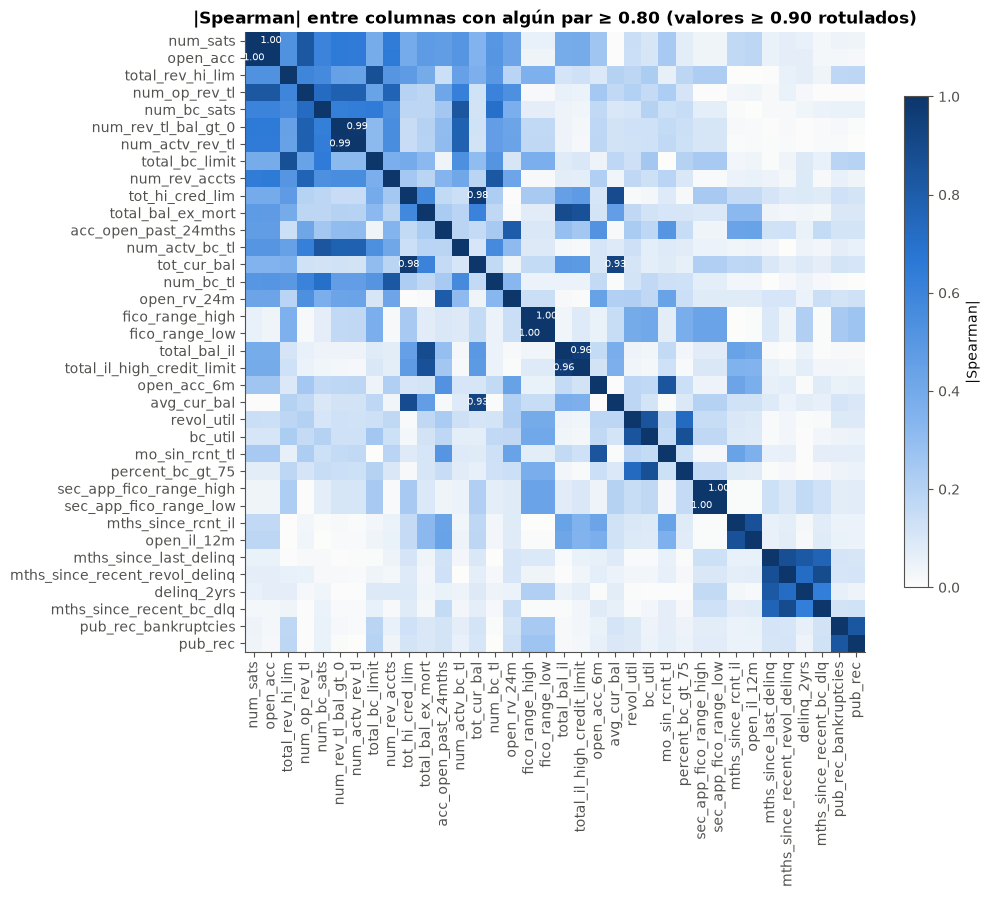

In [12]:
abs_sp = spearman.abs().where(~np.eye(len(spearman), dtype=bool))
en_bloque = abs_sp.columns[(abs_sp >= 0.80).any()]
bloque = spearman.loc[en_bloque, en_bloque].abs()
orden = bloque.mean().sort_values(ascending=False).index
bloque = bloque.loc[orden, orden]
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(bloque, cmap=SECUENCIAL, vmin=0, vmax=1)
ax.set_xticks(range(len(orden)), orden, rotation=90)
ax.set_yticks(range(len(orden)), orden)
for i in range(len(orden)):
    for j in range(len(orden)):
        if i != j and bloque.iloc[i, j] >= UMBRAL_CORRELACION:
            ax.text(j, i, f'{bloque.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7, color='white')
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.75, label='|Spearman|')
ax.set_title('|Spearman| entre columnas con algún par ≥ 0.80 (valores ≥ 0.90 rotulados)')
guardar(fig, 'redundancia_correlacion.png')
plt.show()

## 5. Columnas derivadas de otras

Algunas columnas se calculan a partir de otras. Si la relación es exacta o casi exacta, la derivada no aporta información; si es una razón no lineal, sí puede aportar algo.

In [13]:
diferencia_fico = (X_ent['fico_range_high'] - X_ent['fico_range_low']).value_counts(normalize=True)
print('fico_range_high - fico_range_low:')
print((diferencia_fico * 100).round(3).to_string())

diferencia_sats = (X_ent['open_acc'] - X_ent['num_sats']).dropna()
print(f'\nopen_acc - num_sats: igual en {np.mean(diferencia_sats == 0):.1%}; difiere en 1 o más en {np.mean(diferencia_sats > 0):.1%}')

def correlacion_derivada(objetivo, calculada):
    validas = objetivo.notna() & np.isfinite(calculada)
    return np.corrcoef(objetivo[validas], calculada[validas])[0, 1]

derivadas = pd.DataFrame([
    ('avg_cur_bal', 'tot_cur_bal / open_acc',
     correlacion_derivada(X_ent['avg_cur_bal'], X_ent['tot_cur_bal'] / X_ent['open_acc'])),
    ('revol_util', '100 · revol_bal / total_rev_hi_lim',
     correlacion_derivada(X_ent['revol_util'], 100 * X_ent['revol_bal'] / X_ent['total_rev_hi_lim'])),
    ('bc_util', '100 · (total_bc_limit - bc_open_to_buy) / total_bc_limit',
     correlacion_derivada(X_ent['bc_util'], 100 * (X_ent['total_bc_limit'] - X_ent['bc_open_to_buy']) / X_ent['total_bc_limit'])),
], columns=['columna', 'fórmula aproximada', 'pearson'])
print()
print(derivadas.round(4).to_string(index=False))

print('\napplication_type frente a la presencia de annual_inc_joint:')
print(pd.crosstab(X_ent['application_type'], X_ent['annual_inc_joint'].notna().rename('annual_inc_joint no nulo')))

fico_range_high - fico_range_low:
4.0    99.986
5.0     0.014

open_acc - num_sats: igual en 96.3%; difiere en 1 o más en 3.7%

    columna                                       fórmula aproximada  pearson
avg_cur_bal                                   tot_cur_bal / open_acc   0.9943
 revol_util                       100 · revol_bal / total_rev_hi_lim   0.9814
    bc_util 100 · (total_bc_limit - bc_open_to_buy) / total_bc_limit   0.9639

application_type frente a la presencia de annual_inc_joint:
annual_inc_joint no nulo   False  True 
application_type                       
Individual                846186      0
Joint App                      0  16571


Conclusiones sobre columnas derivadas:

- **`fico_range_high` = `fico_range_low` + 4** en el 99.99 % de los préstamos: es un duplicado desplazado. Se conserva `fico_range_low`, que es la que usa el baseline. Pasa lo mismo con `sec_app_fico_range_high`.
- **`num_sats` ≈ `open_acc`**: coinciden en el 96 % de los casos y casi siempre difieren en una unidad. Se conserva `open_acc`, que tiene menos nulos.
- **Razones** (`avg_cur_bal`, `revol_util`, `bc_util`): salen de dividir dos columnas, con una correlación de 0.98 a 0.99 con la fórmula. No se eliminan, por dos motivos:
  - La razón es una combinación **no lineal** de sus componentes, así que un modelo lineal no la puede reconstruir sumando ambos.
  - Ninguna razón llega a |r| ≥ 0.90 con una columna individual, salvo `avg_cur_bal` con `tot_cur_bal`, y `tot_cur_bal` ya se elimina por su par con `tot_hi_cred_lim`.
- **`application_type`** coincide exactamente con la presencia de las columnas `*_joint` y `sec_app_*`. No es redundante con sus valores: es el indicador que explica sus nulos, lo que interesa al Issue 5.

## 6. Redundancia entre categóricas

Se usan dos medidas:

- **V de Cramér con corrección de sesgo** (Bergsma, 2013). Es simétrica y va de 0 (independientes) a 1 (una determina a la otra). La corrección evita que una variable con muchas categorías aparezca asociada solo por su cardinalidad.
- **U de Theil** (coeficiente de incertidumbre). Es asimétrica: U(x | y) = 1 significa que `y` determina `x`. Sirve para detectar jerarquías, como código postal y estado.

`title` es texto libre (43 mil valores distintos). Antes de medirla se normaliza a minúsculas, se unifican los espacios y se agrupan los 50 títulos más frecuentes, que cubren el 91.6 % de los préstamos con título; el resto va a `otros`. Se excluyen tres tipos de columnas:

- Fechas guardadas como texto (`earliest_cr_line`, `sec_app_earliest_cr_line`): su conversión es ingeniería de variables.
- Texto libre sin otra columna con la que compararse (`emp_title`, `desc`).
- `disbursement_method`, que ya se elimina por casi constante.

In [14]:
categoricas = X_ent.select_dtypes(exclude='number').drop(
    columns=['earliest_cr_line', 'sec_app_earliest_cr_line', 'emp_title', 'desc', 'disbursement_method'],
).copy()
titulo = normalizar_texto(X_ent['title'])
cobertura = titulo.value_counts(normalize=True).iloc[:50].sum()
categoricas['title'] = normalizar_texto(X_ent['title'], top=50)
print(f'Los 50 títulos más frecuentes cubren el {cobertura:.1%} de los préstamos con título.')
print(categoricas.nunique().sort_values().to_string())

nombres = list(categoricas.columns)
cramer = pd.DataFrame(np.eye(len(nombres)), index=nombres, columns=nombres)
for i, a in enumerate(nombres):
    for b in nombres[i + 1:]:
        cramer.loc[a, b] = cramer.loc[b, a] = v_cramer(categoricas[a], categoricas[b])
superior = cramer.where(np.triu(np.ones(cramer.shape, dtype=bool), 1)).stack().sort_values(ascending=False)
print('\nPares con mayor V de Cramér corregida:')
print(superior.head(8).round(3).to_string())

Los 50 títulos más frecuentes cubren el 91.6% de los préstamos con título.
term                           2
application_type               2
verification_status_joint      3
verification_status            3
home_ownership                 6
emp_length                    11
purpose                       14
title                         51
addr_state                    51
zip_code                     934



Pares con mayor V de Cramér corregida:
zip_code             addr_state                   0.994
purpose              title                        0.861
verification_status  verification_status_joint    0.605
home_ownership       zip_code                     0.162
term                 verification_status          0.134
emp_length           verification_status_joint    0.115
home_ownership       addr_state                   0.112
verification_status  title                        0.108


Figura guardada en reports/figures/redundancia_cramer.png


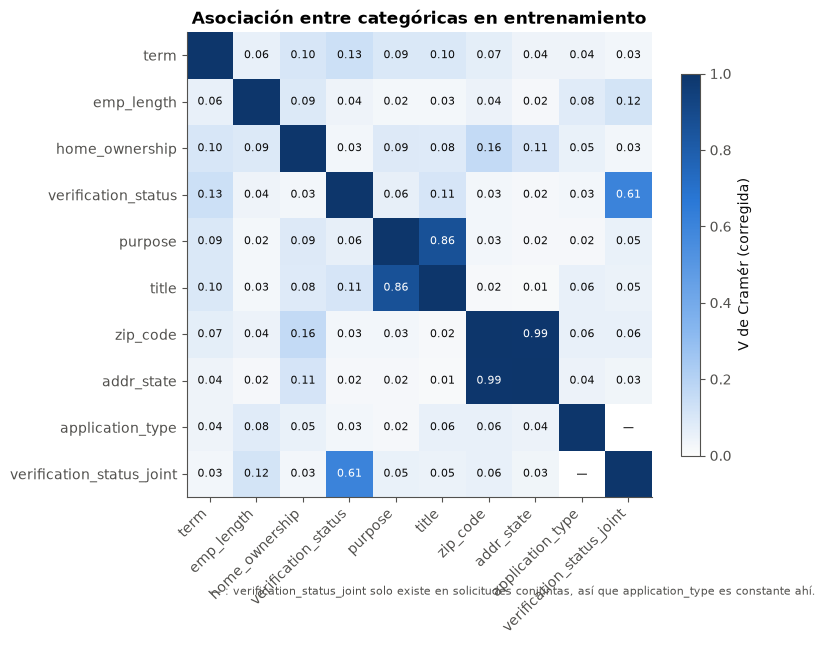

In [15]:
fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(cramer, cmap=SECUENCIAL, vmin=0, vmax=1)
ax.set_xticks(range(len(nombres)), nombres, rotation=45, ha='right')
ax.set_yticks(range(len(nombres)), nombres)
for i in range(len(nombres)):
    for j in range(len(nombres)):
        if i != j:
            valor = cramer.iloc[i, j]
            ax.text(j, i, f'{valor:.2f}' if np.isfinite(valor) else '—', ha='center', va='center', fontsize=8,
                    color='white' if valor >= 0.5 else TINTA)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label='V de Cramér (corregida)')
ax.set_title('Asociación entre categóricas en entrenamiento')
ax.text(0, len(nombres) + 1.6, '— : verification_status_joint solo existe en solicitudes conjuntas, así que application_type es constante ahí.',
        fontsize=8, color=TINTA_2)
guardar(fig, 'redundancia_cramer.png')
plt.show()

### `purpose` frente a `title`

Se mide la asociación en ambas direcciones y se muestra qué `purpose` corresponde a los títulos más comunes.

In [16]:
print(f"V de Cramér (purpose, title):  {cramer.loc['purpose', 'title']:.3f}")
print(f"U(purpose | title) = {u_theil(categoricas['purpose'], categoricas['title']):.3f}  -> cuánto de purpose explica title")
print(f"U(title | purpose) = {u_theil(categoricas['title'], categoricas['purpose']):.3f}  -> cuánto de title explica purpose")
print(f"Nulos: purpose {X_ent['purpose'].isna().mean():.2%}, title {X_ent['title'].isna().mean():.2%}")

cruce = pd.crosstab(categoricas['title'], categoricas['purpose'])
principales = cruce.loc[cruce.sum(axis=1).sort_values(ascending=False).index[:12]]
pd.DataFrame({
    'préstamos': principales.sum(axis=1),
    'purpose principal': principales.idxmax(axis=1),
    '% con ese purpose': (principales.max(axis=1) / principales.sum(axis=1) * 100).round(1),
})

V de Cramér (purpose, title):  0.861
U(purpose | title) = 0.859  -> cuánto de purpose explica title


U(title | purpose) = 0.661  -> cuánto de title explica purpose
Nulos: purpose 0.00%, title 1.24%


,préstamos,purpose principal,% con ese purpose
title,,,
debt consolidation,437414,debt_consolidation,99.7
credit card refinancing,160173,credit_card,99.8
otros,71657,debt_consolidation,49.8
home improvement,50021,home_improvement,99.2
other,42797,other,99.8
major purchase,15689,major_purchase,99.7
medical expenses,8702,medical,99.6
business,7602,small_business,99.2
car financing,7233,car,99.6


**Decisión: se elimina `title` y se conserva `purpose`.**

- La V de Cramér corregida entre ambas es 0.86. Cada título frecuente corresponde a un único `purpose` en el 98.7 % al 99.8 % de los casos; por ejemplo, "debt consolidation" → `debt_consolidation`. Por eso U(purpose | title) = 0.86: el título contiene casi toda la información del propósito.
- La dirección contraria es menor, U(title | purpose) = 0.66, y esa diferencia es la única información extra de `title`. Está en el grupo `otros`, que reúne decenas de miles de textos casi únicos.
- Esa cola, con muy pocos préstamos por texto, no se puede usar sin procesamiento de lenguaje natural.
- `purpose` no tiene nulos, tiene 14 categorías estables y se puede codificar directamente.

### Otras categóricas

In [17]:
print(f"U(addr_state | zip_code) = {u_theil(categoricas['addr_state'], categoricas['zip_code']):.3f}")
print(f"U(zip_code | addr_state) = {u_theil(categoricas['zip_code'], categoricas['addr_state']):.3f}")
estados_por_zip = X_ent.groupby('zip_code')['addr_state'].nunique()
print(f'Códigos zip3 asociados a más de un estado: {np.mean(estados_por_zip > 1):.1%}')

conjuntas = X_ent['application_type'] == 'Joint App'
print(f"\nV de Cramér (verification_status, verification_status_joint), solo conjuntas: "
      f"{v_cramer(X_ent.loc[conjuntas, 'verification_status'], X_ent.loc[conjuntas, 'verification_status_joint']):.3f}")

U(addr_state | zip_code) = 0.997
U(zip_code | addr_state) = 0.541
Códigos zip3 asociados a más de un estado: 55.8%

V de Cramér (verification_status, verification_status_joint), solo conjuntas: 0.605


- **`zip_code` y `addr_state`** (V = 0.99): es una redundancia jerárquica. U(addr_state | zip_code) = 0.997, así que el código postal determina el estado casi por completo. El 55.8 % de los zip3 aparece con más de un estado, pero casi siempre uno de ellos domina; el resto son zonas fronterizas o errores de registro. Lo redundante es `addr_state` *si* se usa `zip_code`, no al revés, porque `zip_code` tiene más detalle. Como el uso de `zip_code` está reservado (decisión 3 de [`analisis_variables.md`](../reports/analisis_variables.md), por su cardinalidad y su sensibilidad geográfica), **no se elimina ninguna de las dos aquí**. La regla queda documentada: si el modelado incorpora `zip_code`, debe quitar `addr_state`.
- **`verification_status` y `verification_status_joint`**: la asociación es moderada aun dentro de las solicitudes conjuntas, porque una describe al solicitante principal y la otra al ingreso conjunto. Se conservan ambas; los nulos de la segunda quedan para el Issue 5.
- **Los demás pares** tienen V ≤ 0.16, sin redundancia.

## 7. `EliminadorRedundantes` ajustado con entrenamiento

El transformador de `src/features.py` aplica todas las reglas anteriores en `fit`. En cada par colineal, el criterio para conservar una columna es:

1. La que tiene menos nulos, porque obliga a imputar menos.
2. Si empatan, la de mayor |Spearman| con el target en entrenamiento.
3. Si siguen empatadas, la que aparece primero en los datos.

`transform` solo quita las columnas aprendidas, así que validación y prueba reciben exactamente las mismas columnas.

In [18]:
eliminador = EliminadorRedundantes().fit(X_ent, y_ent)
eliminadas = eliminador.resumen_eliminadas()
print(f'Se eliminan {len(eliminadas)} de {X_ent.shape[1]} columnas; quedan {len(eliminador.columnas_conservar_)}.')
eliminadas.sort_values('criterio')

Se eliminan 14 de 100 columnas; quedan 86.


,criterio,detalle
columna,,
policy_code,casi constante,el valor `1.0` ocupa el 100.00% de los valores observados
acc_now_delinq,casi constante,el valor `0.0` ocupa el 99.53% de los valores observados
chargeoff_within_12_mths,casi constante,el valor `0.0` ocupa el 99.20% de los valores observados
delinq_amnt,casi constante,el valor `0.0` ocupa el 99.63% de los valores observados
num_tl_120dpd_2m,casi constante,el valor `0.0` ocupa el 99.92% de los valores observados
num_tl_30dpd,casi constante,el valor `0.0` ocupa el 99.68% de los valores observados
disbursement_method,casi constante,el valor `Cash` ocupa el 99.49% de los valores observados
title,categórica redundante,Texto libre que repite `purpose` (V de Cramér alta con `purpose`); `purpose` no tiene nulos y tiene 14 categorías fi...
fico_range_high,colineal,"|r| = 1.000 con `fico_range_low` (Pearson 1.000, Spearman 1.000); se conserva `fico_range_low` por empate (se conser..."


In [19]:
eliminador.decisiones_colineales_.round(3)

,conserva,elimina,max_abs,criterio
0,fico_range_low,fico_range_high,1.000,empate (se conserva la primera)
1,sec_app_fico_range_low,sec_app_fico_range_high,1.000,empate (se conserva la primera)
2,open_acc,num_sats,0.999,menos nulos
3,num_actv_rev_tl,num_rev_tl_bal_gt_0,0.990,mayor relación con el target
4,tot_hi_cred_lim,tot_cur_bal,0.978,mayor relación con el target
5,total_il_high_credit_limit,total_bal_il,0.959,menos nulos


## 8. Comprobación en validación

Eliminar redundancias no debería empeorar el modelo. Se compara una regresión logística con **todas las columnas numéricas** antes y después de aplicar el eliminador. Ambas versiones usan el mismo preprocesamiento del baseline: imputación provisional con la mediana y `StandardScaler`, ajustados solo con entrenamiento.

Se usan solo las numéricas porque la codificación de categóricas no forma parte de este issue. La fila "Baseline (9 variables)" reproduce la referencia del Issue 2.

In [20]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

BASELINE = ('annual_inc', 'dti', 'open_acc', 'pub_rec', 'revol_bal',
            'total_acc', 'fico_range_low', 'delinq_2yrs', 'inq_last_6mths')
X_val_todas, y_val_todas = separar_X_y(validacion)   # sin pisar X_val de issue2

def evaluar(columnas):
    modelo = Pipeline([
        ('imputacion', SimpleImputer(strategy='median')),
        ('escalado', StandardScaler()),
        ('modelo', LogisticRegression(max_iter=1000, random_state=SEED)),
    ]).fit(X_ent[columnas], y_ent)
    prob = modelo.predict_proba(X_val_todas[columnas])[:, 1]
    return {'n_columnas': len(columnas), 'ROC-AUC': roc_auc_score(y_val_todas, prob),
            'PR-AUC': average_precision_score(y_val_todas, prob)}

numericas_todas = list(X_ent.select_dtypes('number').columns.drop('policy_code'))
numericas_limpias = list(eliminador.transform(X_ent).select_dtypes('number').columns)
comparacion = pd.DataFrame({
    'Baseline (9 variables)': evaluar(list(BASELINE)),
    'Numéricas antes del Issue 3': evaluar(numericas_todas),
    'Numéricas después del Issue 3': evaluar(numericas_limpias),
}).T
comparacion['n_columnas'] = comparacion['n_columnas'].astype(int)
comparacion.round(4)

,n_columnas,ROC-AUC,PR-AUC
Baseline (9 variables),9,0.6336,0.2855
Numéricas antes del Issue 3,84,0.6566,0.3090
Numéricas después del Issue 3,73,0.6565,0.3090


`policy_code` se excluye también de la versión "antes", porque es constante y no aporta nada al modelo. La comparación mide solo el efecto de quitar las columnas redundantes informativas.

## 9. Conclusiones

Se eliminan **14 de 100 columnas candidatas**, todas aprendidas solo con entrenamiento. Quedan 86 columnas: 73 numéricas y 13 categóricas o de texto.

| Criterio | Columnas eliminadas | Se conserva en su lugar |
|---|---|---|
| Vacías (100 % nulos) | ninguna | — |
| Casi constantes (≥ 99 % de los valores observados) | `policy_code`, `num_tl_120dpd_2m`, `num_tl_30dpd`, `delinq_amnt`, `acc_now_delinq`, `disbursement_method`, `chargeoff_within_12_mths` | Otras variables de morosidad (`delinq_2yrs`, `num_tl_90g_dpd_24m`, …) |
| Duplicadas exactas | ninguna | — |
| Colineales (\|r\| ≥ 0.90) | `fico_range_high`, `sec_app_fico_range_high`, `num_sats`, `num_rev_tl_bal_gt_0`, `tot_cur_bal`, `total_bal_il` | `fico_range_low`, `sec_app_fico_range_low`, `open_acc`, `num_actv_rev_tl`, `tot_hi_cred_lim`, `total_il_high_credit_limit` |
| Categórica redundante | `title` | `purpose` |

Otras conclusiones:

- **Leakage:** ya se había eliminado en `src/data.py`, y aquí se comprobó que ninguna columna prohibida llegó a los datos. Por eso `funded_amnt`, `funded_amnt_inv`, `grade` y `sub_grade` no aparecen, aunque son redundantes con `loan_amnt` y entre sí.
- **Las 36 columnas con 50 % o más de nulos se conservan** (`sec_app_*`, `*_joint`, `desc`, `mths_since_*`, el bloque de 2016 en adelante) y quedan reportadas para el Issue 5.
- **Se conservan las razones derivadas** (`avg_cur_bal`, `revol_util`, `bc_util`), porque son combinaciones no lineales de sus componentes.
- **`zip_code` y `addr_state` también se conservan:** forman una jerarquía, pero su uso depende de una decisión pendiente sobre `zip_code`.
- **En validación, eliminar estas columnas no cambia el desempeño.** El ROC-AUC pasa de 0.6566 a 0.6565 y el PR-AUC se mantiene en 0.3090, con 11 columnas numéricas menos. Las columnas eliminadas no aportaban información nueva al modelo lineal.
- **El aumento frente al baseline** (0.6336 → 0.6565) viene de usar todas las numéricas en lugar de 9, no de este issue.

Para usar estas decisiones en otro notebook basta con empezar con `%run issue3.ipynb` (ver sección 10).

## 10. Salida para los issues siguientes

Se quitan de `X_train`, `X_val` y `X_test` (las de `issue2.ipynb`) las columnas que el `EliminadorRedundantes` marcó como redundantes y que siguen presentes. Algunas ya las había quitado `issue2` (más de 90 % de nulos, casi constantes, `title`).

In [21]:
redundantes = [col for col in eliminador.columnas_eliminar_ if col in X_train.columns]
X_train = X_train.drop(columns=redundantes)
X_val = X_val[X_train.columns]
X_test = X_test[X_train.columns]

print(f'Redundantes quitadas de X_train: {redundantes}')
print(f'X_train: {X_train.shape} | X_val: {X_val.shape} | X_test: {X_test.shape}')

Redundantes quitadas de X_train: ['fico_range_high', 'tot_cur_bal', 'total_bal_il', 'num_rev_tl_bal_gt_0', 'num_sats', 'num_tl_120dpd_2m', 'num_tl_30dpd']
X_train: (862757, 69) | X_val: (215690, 69) | X_test: (269612, 69)


## Checkpoint

Se guardan las particiones en `data/checkpoints/issue3/` para que `issue4.ipynb` las cargue sin volver a ejecutar la cadena.

In [22]:
from src.checkpoints import guardar_checkpoint

guardar_checkpoint('issue3', X_train=X_train, X_val=X_val, X_test=X_test,
                   y_train=y_train, y_val=y_val, y_test=y_test)

Checkpoint issue3: X_train (862757, 69) guardado


Checkpoint issue3: X_val (215690, 69) guardado


Checkpoint issue3: X_test (269612, 69) guardado


Checkpoint issue3: y_train (862757, 1) guardado
Checkpoint issue3: y_val (215690, 1) guardado
Checkpoint issue3: y_test (269612, 1) guardado
Checkpoint guardado en D:\UTEC\ML\Proyecto\Prediction-With-Machine-Learning-Lending-Club\data\checkpoints\issue3
